## Search in max membership coefficient

In [ ]:
K_value=6

snmf_folder="../01-snmf/out/All_data_wo_orientalis/s01.snmf/K_value"
faststructure_folder="../02-fastStructure/out/All_data_wo_orientalis/s05.membership_coefficient"

In [59]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

# Get the first file in the folder matching the pattern
snmf_file = next((f for f in os.listdir(snmf_folder) if re.search(str(K_value), f)), None)
print(f"snmf_file: {snmf_file}")
if snmf_file is None:
    raise FileNotFoundError(f"No file found in {snmf_folder} matching K_value {K_value}")

# Read the file using pandas
snmf_file_path = os.path.join(snmf_folder, snmf_file)
snmf_df = pd.read_csv(snmf_file_path, sep=",", header=0)

# Keep only the first column and the column starting with V
cols_to_keep = [snmf_df.columns[0]] + [col for col in snmf_df.columns if col.startswith("V")]
snmf_df = snmf_df[cols_to_keep]
print(snmf_df.head())

# Get the first file in the folder matching the pattern
faststructure_file = next((f for f in os.listdir(faststructure_folder) if re.search(str(K_value), f)), None)
print(f"faststructure_file: {faststructure_file}")
if faststructure_file is None:
    raise FileNotFoundError(f"No file found in {faststructure_folder} matching K_value {K_value}")

# Read the file using pandas
faststructure_file_path = os.path.join(faststructure_folder, faststructure_file)
faststructure_df = pd.read_csv(faststructure_file_path, sep=",", header=0)
# Keep only the first column and the column starting with V
cols_to_keep = [faststructure_df.columns[0]] + [col for col in faststructure_df.columns if col.startswith("V")]
faststructure_df = faststructure_df[cols_to_keep]
print(faststructure_df.head())

snmf_file: K6_value_sorted.csv
  Seq_ID        V1        V2        V3        V4        V5        V6
0   A011  0.002378  0.013891  0.925239  0.017051  0.029683  0.011757
1   A012  0.000100  0.030797  0.938270  0.001613  0.027213  0.002007
2   A015  0.000100  0.000100  0.980098  0.000100  0.000100  0.019502
3   A016  0.007448  0.021119  0.895514  0.000100  0.049322  0.026496
4   A017  0.000100  0.000100  0.999500  0.000100  0.000100  0.000100
faststructure_file: K6_value_sorted.csv
  Seq_ID      V1      V2   V3   V4   V5   V6
0   A011  0.0000  1.0000  0.0  0.0  0.0  0.0
1   A012  0.0000  1.0000  0.0  0.0  0.0  0.0
2   A015  0.0000  1.0000  0.0  0.0  0.0  0.0
3   A016  0.0075  0.9925  0.0  0.0  0.0  0.0
4   A017  0.0000  1.0000  0.0  0.0  0.0  0.0


In [62]:
# Function to attribute a group depending of the value of the column
def assign_group(df):
    # Identify V columns
    v_cols = [col for col in df.columns if col.startswith("V")]
    
    # Function to apply to each row
    def get_group(row):
        for col in v_cols:
            if row[col] >= 0.8:
                return col
        return "unsign"
    
    # Apply the function row-wise
    df["group"] = df.apply(get_group, axis=1)
    return df


In [63]:
# Use the function to create a new column in the dataframe
snmf_df = assign_group(snmf_df)
#print(snmf_df)


# Count the occurrences of each group
group_counts = snmf_df["group"].value_counts()
print(group_counts)
# Create a bar plot
#plt.figure(figsize=(10, 6))
#group_counts.plot(kind="bar")
#plt.title("Group Counts snmf")
#plt.xlabel("Group")
#plt.ylabel("Count")
#plt.xticks(rotation=45)
#plt.tight_layout()


unsign    51
V5        23
V1        22
V3        18
V4        16
V6         9
V2         9
Name: group, dtype: int64


For snmf:
- V6 = 
- V5 = ROM
- V4 = FR
- V3 = AUS
- V2 = 
- V1

In [64]:
# Use the function to create a new column in the dataframe
faststructure_df = assign_group(faststructure_df)
#print(faststructure_df)

# Count the occurrences of each group
group_counts = faststructure_df["group"].value_counts()
print(group_counts)
# Create a bar plot
#plt.figure(figsize=(10, 6))
#group_counts.plot(kind="bar")
#plt.title("Group Counts faststructure")
#plt.xlabel("Group")
#plt.ylabel("Count")
#plt.xticks(rotation=45)
#plt.tight_layout()

V1        44
unsign    33
V3        23
V2        18
V5        16
V4         9
V6         5
Name: group, dtype: int64


In [47]:
# Merge the two dataframes on the first column
merged_df = pd.merge(snmf_df, faststructure_df, on=snmf_df.columns[0], suffixes=('_snmf', '_faststructure'))
print(merged_df.head())

# Savve the merged dataframe to a CSV file
output_file = f"merged_snmf_faststructure_K{K_value}.csv"
merged_df.to_csv(output_file, index=False)
print(f"Merged dataframe saved to {output_file}")

  Seq_ID   V1_snmf   V2_snmf   V3_snmf   V4_snmf   V5_snmf group_snmf  \
0   A011  0.930499  0.010156  0.000100  0.035437  0.023809         V1   
1   A012  0.939290  0.031858  0.000100  0.028627  0.000125         V1   
2   A015  0.995869  0.000100  0.000100  0.003831  0.000100         V1   
3   A016  0.899336  0.024195  0.006222  0.070147  0.000100         V1   
4   A017  0.999600  0.000100  0.000100  0.000100  0.000100         V1   

   V1_faststructure  V2_faststructure  V3_faststructure  V4_faststructure  \
0            0.0000            1.0000               0.0               0.0   
1            0.0000            1.0000               0.0               0.0   
2            0.0000            1.0000               0.0               0.0   
3            0.0122            0.9877               0.0               0.0   
4            0.0000            1.0000               0.0               0.0   

   V5_faststructure group_faststructure  
0               0.0                  V2  
1             

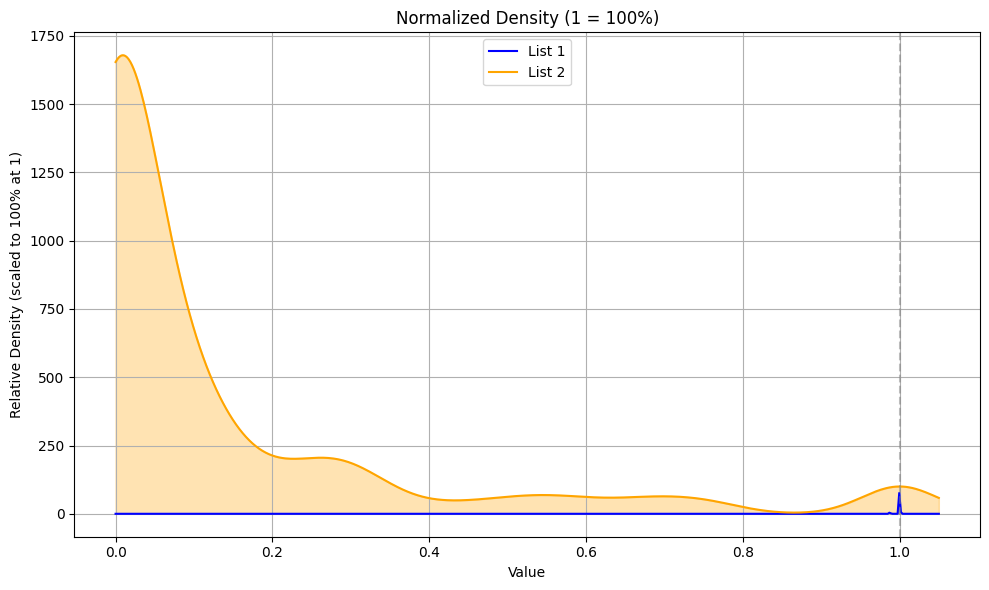

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import gaussian_kde

# Input lists
list1 = [1, 1, 1, 0.9877, 1, 1, 1, 1, 1, 1, 1, 1, 1]

list2 = [
    0.1853, 0.2149, 0.0918, 0.1349, 0.1114, 0, 0.1442, 0.0609, 0, 0.0001, 0.0881, 0.0826, 0, 0, 0,
    1, 0.1829, 0.4194, 0.2099, 0.1481, 0.1087, 0.0603, 0.0518, 0, 0.0804, 0.0697, 0.0878, 0, 0.0616,
    0.3494, 0.0361, 0, 0, 0.3041, 0.0979, 0.0023, 0.2558, 0.0021, 0, 0.303, 1, 0.0005, 0.0443, 0,
    0.0537, 0.2705, 0.1273, 0.0006, 1, 0.0675, 0.0395, 0.0388, 0.6762, 0, 0, 0, 0, 0, 0, 0, 0.0969,
    0, 0, 0, 0, 0, 0.0125, 0.0517, 0, 0, 0.1063, 0, 0.1555, 0, 0, 0.2381, 0, 0, 0, 0.0017, 0.0008,
    0.2697, 0.5403, 0.6825, 0.0995, 0.1127, 0.7591, 0, 0, 0.033, 0.6099, 0, 0, 0, 0, 0.0029, 0, 0,
    0, 0, 0, 0, 0, 0, 0.0059, 0, 0.2626, 0.0741, 0, 0, 0, 0, 0, 0.0022, 0, 0.5154, 0.7406, 0, 0,
    0.3352, 1, 0.067, 0, 0.0032, 0, 0.2827, 0.0009, 0.5752, 0, 1, 0, 0.472, 0.3089, 0.0001, 0.0146
]

# Create a range for x values
x_vals = np.linspace(0, 1.05, 500)

# Estimate KDEs
kde1 = gaussian_kde(list1, bw_method=0.2)
kde2 = gaussian_kde(list2, bw_method=0.2)

y1 = kde1(x_vals)
y2 = kde2(x_vals)

# Normalize so that value at x=1 is 100%
max_at_1_list1 = kde1(1.0)[0]
max_at_1_list2 = kde2(1.0)[0]

y1_percent = (y1 / max_at_1_list1) * 100
y2_percent = (y2 / max_at_1_list2) * 100

# Plot
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y1_percent, label='List 1', color='blue')
plt.plot(x_vals, y2_percent, label='List 2', color='orange')
plt.fill_between(x_vals, y1_percent, alpha=0.3, color='blue')
plt.fill_between(x_vals, y2_percent, alpha=0.3, color='orange')

# Labels and formatting
plt.xlabel("Value")
plt.ylabel("Relative Density (scaled to 100% at 1)")
plt.title("Normalized Density (1 = 100%)")
plt.axvline(x=1, linestyle='--', color='gray', alpha=0.5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


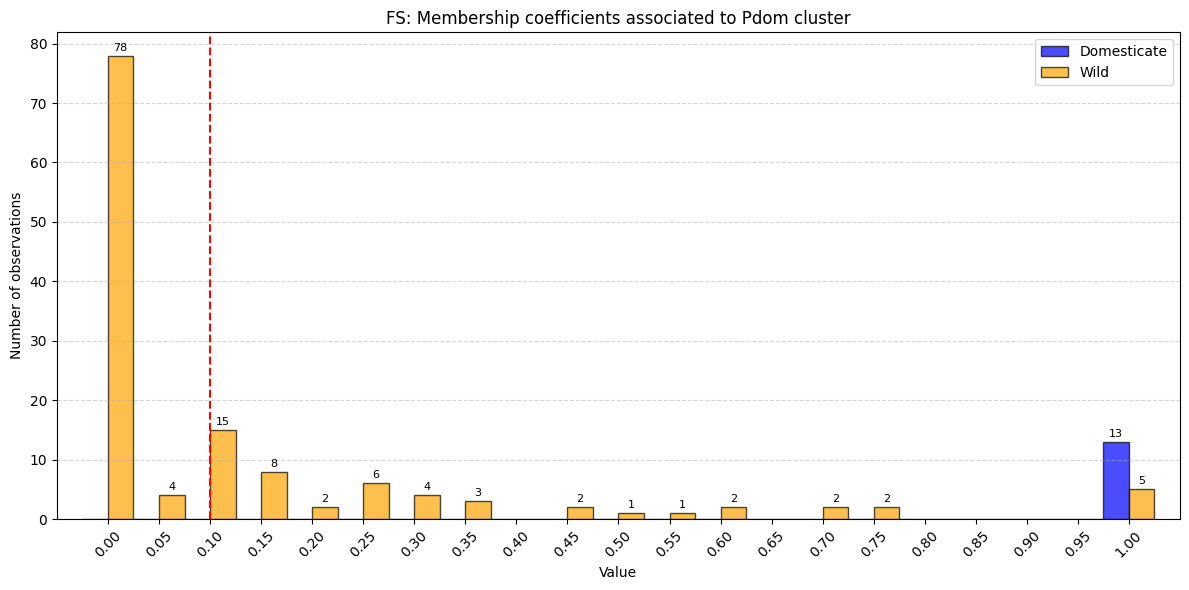

In [24]:
# FastStructure plot

import matplotlib.pyplot as plt
import numpy as np

# Données
list1 = [
    1.00, 1.00, 1.00, 0.99, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00, 1.00
]

list2 = [
    0.20, 0.23, 0.11, 0.15, 0.13, 0.00, 0.16, 0.08, 0.00, 0.00, 0.10, 0.10, 0.00, 0.00, 0.00,
    1.00, 0.20, 0.43, 0.23, 0.16, 0.13, 0.09, 0.08, 0.00, 0.11, 0.09, 0.12, 0.00, 0.09, 0.37,
    0.00, 0.00, 0.00, 0.31, 0.12, 0.00, 0.26, 0.00, 0.00, 0.31, 1.00, 0.00, 0.06, 0.00, 0.02,
    0.27, 0.13, 0.00, 1.00, 0.00, 0.00, 0.00, 0.68, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00,
    0.12, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.12, 0.00, 0.16, 0.00, 0.00,
    0.24, 0.00, 0.00, 0.00, 0.00, 0.00, 0.28, 0.55, 0.69, 0.12, 0.14, 0.77, 0.00, 0.00, 0.04,
    0.61, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.01,
    0.00, 0.26, 0.08, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.52, 0.75, 0.00, 0.00, 0.34,
    1.00, 0.06, 0.00, 0.00, 0.00, 0.28, 0.00, 0.58, 0.00, 1.00, 0.00, 0.47, 0.33, 0.00, 0.03
]

# Bins avec un centre à 0
step = 0.05
bins = np.arange(-step/2, 1 + step, step)  # Commence à -0.025, se termine à 1.0
bin_centers = bins[:-1] + step / 2

# Comptages
counts1, _ = np.histogram(list1, bins=bins)
counts2, _ = np.histogram(list2, bins=bins)

# Tracé
plt.figure(figsize=(12, 6))
bars1 = plt.bar(bin_centers - step/4, counts1, width=step/2, alpha=0.7, label="Domesticate", color="blue", edgecolor='black')
bars2 = plt.bar(bin_centers + step/4, counts2, width=step/2, alpha=0.7, label="Wild", color="orange", edgecolor='black')

# Affichage des valeurs au-dessus des barres
for bar in bars1 + bars2:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.5, str(height), ha='center', va='bottom', fontsize=8)

# Axes
plt.xlabel("Value")
plt.ylabel("Number of observations")
plt.title("FS: Membership coefficients associated to Pdom cluster")
plt.xticks(bin_centers, [f"{x:.2f}" for x in bin_centers], rotation=45)
plt.xlim(-0.05, 1.05)
plt.legend()
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.axvline(x=0.1, linestyle='--', color='red', alpha=1)
#plt.show()

#save the plot
plt.savefig("../out/s03.structure_plot_spe/membership_coefficients_Pdom_cluster_FS.png", dpi=300)
# as svg
plt.savefig("../out/s03.structure_plot_spe/membership_coefficients_Pdom_cluster_FS.svg")

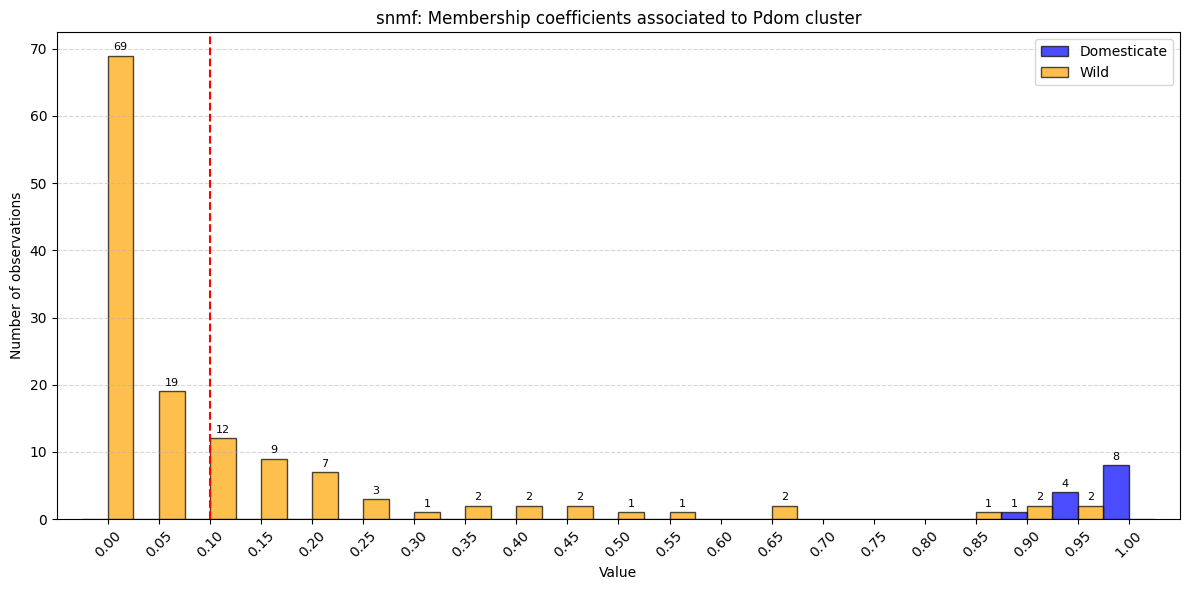

In [25]:
# snmf plot
import matplotlib.pyplot as plt
import numpy as np

list1 = [
    0.925239, 0.93827, 0.980098, 0.895514, 0.9995, 0.9995, 0.9995,
    0.9995, 0.9995, 0.949415, 0.9995, 0.958728, 0.993181
]

list2 = [
    0.137567, 0.21275, 0.121212, 0.164978, 0.127895, 9.9973e-05, 0.176643, 0.101823, 9.9973e-05, 0.0116774,
    0.0500425, 0.0597646, 0.00252107, 0.00425524, 0.0336992, 0.931843, 0.133161, 0.354126, 0.155195, 0.121912,
    0.0900804, 0.0616124, 0.0348905, 9.996e-05, 0.0656408, 0.0433325, 0.0818257, 9.996e-05, 0.0950976, 0.304227,
    9.996e-05, 9.9982e-05, 9.9982e-05, 0.20791, 0.159141, 0.00765387, 0.170725, 9.9964e-05, 9.9973e-05, 0.22334,
    0.962577, 0.010512, 0.0417451, 9.996e-05, 0.0113448, 0.181805, 0.0865497, 9.9991e-05, 0.906208, 0.0179394,
    9.996e-05, 9.996e-05, 0.519565, 9.996e-05, 0.00243403, 9.9973e-05, 9.996e-05, 9.996e-05, 9.9973e-05, 0.0148306,
    0.079594, 9.9973e-05, 0.00341844, 9.9982e-05, 9.9973e-05, 0.0118487, 9.9973e-05, 9.9964e-05, 9.9964e-05,
    9.9982e-05, 0.144012, 0.00224711, 0.0913406, 9.9964e-05, 9.9973e-05, 0.143832, 9.9973e-05, 9.9964e-05, 9.996e-05,
    9.9982e-05, 0.0233845, 0.245974, 0.434884, 0.552985, 0.113657, 0.0980056, 0.639337, 9.9973e-05, 0.0374648,
    0.036593, 0.453045, 9.9982e-05, 0.0127272, 0.0311803, 0.0482818, 0.0556751, 0.0517926, 0.010592, 0.0122948,
    0.0170065, 9.9982e-05, 9.996e-05, 9.9973e-05, 0.0253814, 0.0474979, 0.000144803, 0.205656, 0.0878586, 9.9964e-05,
    9.9982e-05, 9.9991e-05, 9.9964e-05, 9.9991e-05, 0.0315935, 0.00232865, 0.414049, 0.634954, 9.9973e-05,
    9.9964e-05, 0.231035, 0.908262, 0.0290435, 0.00574653, 0.00395134, 9.9973e-05, 0.223114, 0.0209537, 0.413868,
    9.996e-05, 0.873434, 0.0155463, 0.370542, 0.246872, 0.0316058, 0.0238961
]


# Bins avec un centre à 0
step = 0.05
bins = np.arange(-step/2, 1 + step, step)  # Commence à -0.025, se termine à 1.0
bin_centers = bins[:-1] + step / 2

# Comptages
counts1, _ = np.histogram(list1, bins=bins)
counts2, _ = np.histogram(list2, bins=bins)

# Tracé
plt.figure(figsize=(12, 6))
bars1 = plt.bar(bin_centers - step/4, counts1, width=step/2, alpha=0.7, label="Domesticate", color="blue", edgecolor='black')
bars2 = plt.bar(bin_centers + step/4, counts2, width=step/2, alpha=0.7, label="Wild", color="orange", edgecolor='black')

# Affichage des valeurs au-dessus des barres
for bar in bars1 + bars2:
    height = bar.get_height()
    if height > 0:
        plt.text(bar.get_x() + bar.get_width()/2, height + 0.5, str(height), ha='center', va='bottom', fontsize=8)

# Axes
plt.xlabel("Value")
plt.ylabel("Number of observations")
plt.title("snmf: Membership coefficients associated to Pdom cluster")
plt.xticks(bin_centers, [f"{x:.2f}" for x in bin_centers], rotation=45)
plt.xlim(-0.05, 1.05)
plt.legend()
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout() 
# add a vertical line at x=0.1
plt.axvline(x=0.1, linestyle='--', color='red', alpha=1)

#plt.show()

# Save the plot
plt.savefig("../out/s03.structure_plot_spe/membership_coefficients_Pdom_cluster_snmf.png", dpi=300)
# Save as SVG
plt.savefig("../out/s03.structure_plot_spe/membership_coefficients_Pdom_cluster_snmf.svg")